# Machine Learning - Lab Assignment
## Linear Regression, Ridge and Lasso

Name: __________________________    Group: __________    Date: __________

Use Python 3 and Jupyter Notebook. Required packages: `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If needed, install them with `pip install numpy pandas matplotlib scikit-learn`.

Work through the tasks in order. Create the dataset in Task 1; no external file is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Task 1. Generate the dataset

Create a DataFrame named `df` with 500 synthetic salary records:

- Set the NumPy random seed to **42**.
- Generate 500 integers for `YearsOfExperience`, between **2 and 20 inclusive**, with `np.random.randint(2, 21, size=500)`.
- Set `intercept = 60000` and `slope = (200000 - 60000) / (20 - 2)`.
- Generate 500 noise values from a normal distribution using `np.random.normal(0, 10000, size=500)`.
- Compute `Salary = intercept + slope * YearsOfExperience + noise`.
- Use pandas to create `df` with exactly two columns: `YearsOfExperience` and `Salary`. Display its first five rows and check that its shape is `(500, 2)`.

Generate the experience values **before** generating the noise. Do not load a dataset from a file.

In [2]:
np.random.seed(42)
nember_of_samples = 500

years_of_experience = np.random.randint(2, 21, size=nember_of_samples)


intercept = 60000
slope = (200000 - 60000) / (20 - 2)


noise = np.random.normal(0, 10000, size=500)


salary = intercept + slope * years_of_experience + noise


df = pd.DataFrame({
    "YearsOfExperience": years_of_experience,
    "Salary": salary
})
print("--- Task 1: Dataset Head & Shape ---")
print("Shape:", df.shape)
print(df.head(), "\n")

--- Task 1: Dataset Head & Shape ---
Shape: (500, 2)
   YearsOfExperience         Salary
0                  8  115037.780010
1                 16  182309.972927
2                 12  156442.408989
3                  9  144753.562169
4                  8  130798.818454 



### Task 2. Explore the dataset

Display the dataset shape, summary statistics and number of missing values in each column. Calculate the correlation between `YearsOfExperience` and `Salary`.

In [3]:
print("--- Task 2: Dataset Exploration ---")

print("Shape:", df.shape)
print("\nSummary Statistics:")
print(df.describe())
print("\nMissing-value counts:")
print(df.isnull().sum())


correlation = df["YearsOfExperience"].corr(df["Salary"])
print(f"\nCorrelation between YearsOfExperience and Salary: {correlation:.4f}\n")

--- Task 2: Dataset Exploration ---
Shape: (500, 2)

Summary Statistics:
       YearsOfExperience         Salary
count         500.000000     500.000000
mean           10.616000  142570.011096
std             5.662922   44935.263058
min             2.000000   54881.134555
25%             5.750000  104426.300731
50%            10.000000  139865.032545
75%            16.000000  182341.125962
max            20.000000  241879.376204

Missing-value counts:
YearsOfExperience    0
Salary               0
dtype: int64

Correlation between YearsOfExperience and Salary: 0.9751



### Task 3. Plot the data

Draw a scatter plot with `YearsOfExperience` on the x-axis and `Salary` on the y-axis. Add axis labels and a title.

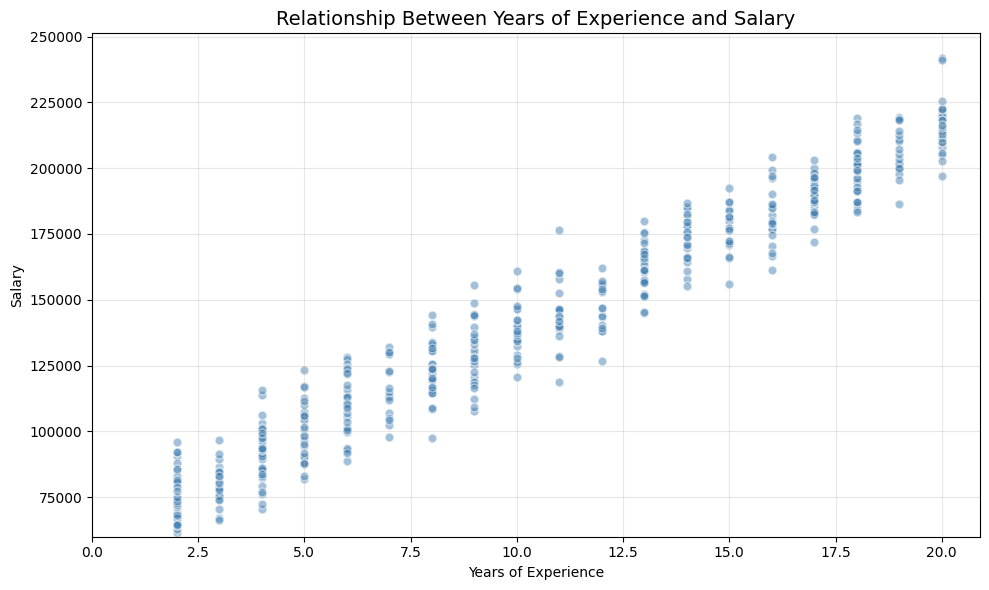

In [4]:
plt.figure(figsize=(10, 6))
plt.scatter(df["YearsOfExperience"], df["Salary"], alpha=0.5, color="steelblue", edgecolor="white", s=40)


plt.ylim(bottom=60000)
plt.xlim(left=0)
plt.title("Relationship Between Years of Experience and Salary", fontsize=14)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 4. Split the dataset

Set `X` to the `YearsOfExperience` column as a two-dimensional DataFrame and `y` to `Salary`. Use `train_test_split` with `test_size=0.20` and `random_state=42`. Display the number of training and test records.

In [5]:
x = df[["YearsOfExperience"]]
y = df["Salary"]


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

### Task 5. Train linear regression

Fit a `LinearRegression` model on the training data. Display the slope, intercept, training R2 and test R2.

In [10]:
model = LinearRegression()
model.fit(x_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_

train_r2 = model.score(x_train, y_train)
test_r2 = model.score(x_test, y_test)

### Task 6. Evaluate linear regression

Predict salary for the test set. Calculate MAE, MSE, RMSE and R2. Display the first five actual and predicted salaries in a table.

In [11]:
salary_pred = model.predict(x_test)
mae = mean_absolute_error(y_test, salary_pred)
mse = mean_squared_error(y_test, salary_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, salary_pred)

### Task 7. Compare with a baseline

Use the mean of `y_train` as the predicted salary for every test record. Compute baseline MAE and RMSE and compare them with linear regression.

In [12]:
mean_salary = y_train.mean()
baseline_pred = np.full_like(y_test, mean_salary)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
print("--- Task 7: Baseline Comparison ---")
print(f"Linear Regression:\n\tMAE: {mae:.4f}\n\tMSE: {mse:.4f}\n\tRMSE: {rmse:.4f}\n\tR2: {r2:.4f}")

print(f"Baseline:\n\tMAE: {baseline_mae:.4f}\n\tMSE: {baseline_mse:.4f}\n\tRMSE: {baseline_rmse:.4f}\n")

--- Task 7: Baseline Comparison ---
Linear Regression:
	MAE: 7905.1147
	MSE: 93933277.3795
	RMSE: 9691.9181
	R2: 0.9574
Baseline:
	MAE: 40444.9579
	MSE: 2204656471.2017
	RMSE: 46953.7695



### Task 8. Plot predictions and residuals

Make two graphs: (a) test observations and the fitted regression line; (b) residuals (`actual - predicted`) against years of experience, with a horizontal line at zero.

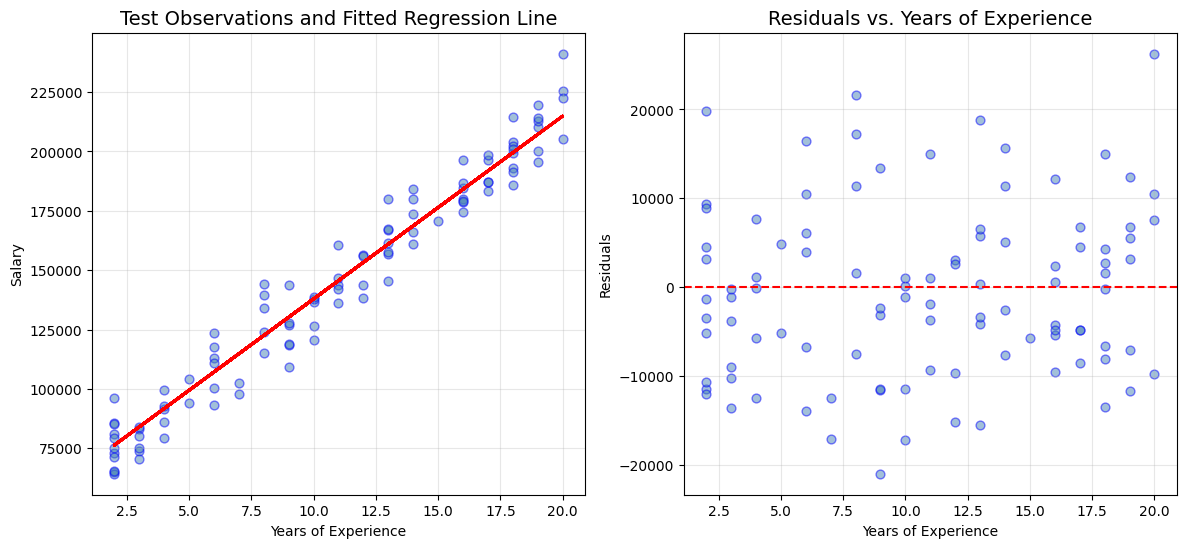

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
y_pred = model.predict(x_test)

axs[0].scatter(x_test, y_test, alpha=0.5, color="steelblue", edgecolor="blue", s=40)
axs[0].plot(x_test, y_pred, color="red", linewidth=2)
axs[0].set_title("Test Observations and Fitted Regression Line", fontsize=14)
axs[0].set_xlabel("Years of Experience")
axs[0].set_ylabel("Salary")
axs[0].grid(True, alpha=0.3)

axs[1].scatter(x_test, y_test - y_pred, alpha=0.5, color="steelblue", edgecolor="blue", s=40)
axs[1].axhline(y=0, color="red", linestyle="--")
axs[1].set_title("Residuals vs. Years of Experience", fontsize=14)
axs[1].set_xlabel("Years of Experience")
axs[1].set_ylabel("Residuals")
axs[1].grid(True, alpha=0.3)

### Task 9. Predict new salaries

Use the linear regression model to predict salaries for **5, 10 and 15 years** of experience. Display the results in a table.

In [14]:
years_of_experience_new = np.array([[5], [10], [15]])
predicted_salaries = model.predict(years_of_experience_new)
results = pd.DataFrame({
    "Years of Experience": years_of_experience_new.flatten(),
    "Predicted Salary": predicted_salaries
})

print("--- Task 9: Predicted Salaries ---")
print(results)

--- Task 9: Predicted Salaries ---
   Years of Experience  Predicted Salary
0                    5      99444.405496
1                   10     137927.470111
2                   15     176410.534726


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


### Task 10. Standardize the feature

Use `StandardScaler` on `X_train` and `X_test`. Fit the scaler on the training set only, then transform both sets. Keep the target `y` unchanged.

In [15]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### Task 11. Train Ridge regression

Fit two `Ridge` models on the scaled training set, using `alpha=10` and `alpha=100`. For each model, display its coefficient, test MAE and test R2. Compare the coefficients. Keep the `alpha=10` model for Task 13.

In [18]:
ridge_model_10 = Ridge(alpha=10)
ridge_model_10.fit(x_train_scaled, y_train)

ridge_model_100 = Ridge(alpha=100)
ridge_model_100.fit(x_train_scaled, y_train)
test_pred_10 = ridge_model_10.predict(x_test_scaled)
test_pred_100 = ridge_model_100.predict(x_test_scaled)
mae_10 = mean_absolute_error(y_test, test_pred_10)
mae_100 = mean_absolute_error(y_test, test_pred_100)
r2_10 = r2_score(y_test, test_pred_10)
r2_100 = r2_score(y_test, test_pred_100)
print("--- Task 11: Ridge Regression Coefficients ---")
print("Alpha\t\tCoefficient\t\tMAE\t\tR2")
print(f"10\t\t{ridge_model_10.coef_[0]:.4f}\t\t{mae_10:.4f}\t\t{r2_10:.4f}")
print(f"100\t\t{ridge_model_100.coef_[0]:.4f}\t\t{mae_100:.4f}\t\t{r2_100:.4f}")

--- Task 11: Ridge Regression Coefficients ---
Alpha		Coefficient		MAE		R2
10		42156.5031		8084.4613		0.9557
100		34568.3325		11308.3700		0.9118


### Task 12. Train Lasso regression

Fit three `Lasso` models on the scaled training set, using `alpha=1000`, `alpha=10000` and `alpha=50000`. Set `max_iter=20000`. For each model, display its coefficient, test MAE and test R2. Observe what happens to the coefficient as alpha increases. Keep the `alpha=1000` model for Task 13.

In [20]:
lasso_model_1000 = Lasso(alpha=1000, max_iter=20000)
lasso_model_1000.fit(x_train_scaled, y_train)

lasso_model_10000 = Lasso(alpha=10000, max_iter=20000)
lasso_model_10000.fit(x_train_scaled, y_train)

lasso_model_50000 = Lasso(alpha=50000, max_iter=20000)
lasso_model_50000.fit(x_train_scaled, y_train)

test_pred_1000 = lasso_model_1000.predict(x_test_scaled)
test_pred_10000 = lasso_model_10000.predict(x_test_scaled)
test_pred_50000 = lasso_model_50000.predict(x_test_scaled)

mae_1000 = mean_absolute_error(y_test, test_pred_1000)
mae_10000 = mean_absolute_error(y_test, test_pred_10000)
mae_50000 = mean_absolute_error(y_test, test_pred_50000)

r2_1000 = r2_score(y_test, test_pred_1000)
r2_10000 = r2_score(y_test, test_pred_10000)
r2_50000 = r2_score(y_test, test_pred_50000)

print("--- Task 12: Lasso Regression ---")
print("Alpha\t\tCoefficient\t\tMAE\t\tR2")
print(f"1000\t\t{lasso_model_1000.coef_[0]:.4f}\t\t{mae_1000:.4f}\t\t{r2_1000:.4f}")
print(f"10000\t\t{lasso_model_10000.coef_[0]:.4f}\t\t{mae_10000:.4f}\t\t{r2_10000:.4f}")
print(f"50000\t\t{lasso_model_50000.coef_[0]:.4f}\t\t{mae_50000:.4f}\t\t{r2_50000:.4f}")

--- Task 12: Lasso Regression ---
Alpha		Coefficient		MAE		R2
1000		42210.4157		8074.6515		0.9558
10000		33210.4157		12287.9627		0.8980
50000		0.0000		40444.9579		-0.0005


### Task 13. Compare the models

Create a table showing test MAE, RMSE and R2 for: the mean baseline, linear regression, Ridge (`alpha=10`) and Lasso (`alpha=1000`). Write two sentences about the results.

In [21]:
mean_baseline_mae = mean_absolute_error(y_test, baseline_pred)
mean_baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
mean_baseline_r2 = r2_score(y_test, baseline_pred)
ridge_mae = mean_absolute_error(y_test, ridge_model_10.predict(x_test_scaled))
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_model_10.predict(x_test_scaled)))
ridge_r2 = r2_score(y_test, ridge_model_10.predict(x_test_scaled))
lasso_mae = mean_absolute_error(y_test, lasso_model_1000.predict(x_test_scaled))
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_model_1000.predict(x_test_scaled)))
lasso_r2 = r2_score(y_test, lasso_model_1000.predict(x_test_scaled))
print("--- Task 13: Model Comparison ---")
print("Model\t\tMAE\t\tRMSE\t\tR2")
print(f"Mean Baseline\t{mean_baseline_mae:.4f}\t{mean_baseline_rmse:.4f}\t{mean_baseline_r2:.4f}")
print(f"Linear Regression\t{mae:.4f}\t{rmse:.4f}\t{r2:.4f}")
print(f"Ridge (alpha=10)\t{ridge_mae:.4f}\t{ridge_rmse:.4f}\t{ridge_r2:.4f}")

print(f"Lasso (alpha=1000)\t{lasso_mae:.4f}\t{lasso_rmse:.4f}\t{lasso_r2:.4f}")

--- Task 13: Model Comparison ---
Model		MAE		RMSE		R2
Mean Baseline	40444.9579	46953.7695	-0.0005
Linear Regression	7905.1147	9691.9181	0.9574
Ridge (alpha=10)	8084.4613	9876.9316	0.9557
Lasso (alpha=1000)	8074.6515	9864.6082	0.9558


**Submission:** Save the notebook with your code, results and plots. Include your short comparison for Task 13.